**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**02 | Gap-Aware Gaze Preprocessing and Velocity**

![Gap-aware preprocessing: recorded Notebook 01 gaze input and clearly labelled method diagrams](../../images/02_gap_aware_gaze_preprocessing.svg)

**Objective:** Construct a source-aligned, gap-respecting offline gaze representation and adjacent-sample angular velocity for later fixation and saccade analysis.

**Notebook 01 input evidence:** The committed source audit selected **10 participants**, **40 task recordings** and **2,778,008 samples** from GazeBase Round 1, Session 1. Notebook 02 consumes its saved `01_gaze_samples.csv`, `01_source_manifest.csv` and `01_quality_by_record.csv`; it does not redownload GazeBase.

**Method scope:** Read complete recordings independently, retain original positions, timestamps, validity and source identities, and derive smoothed coordinates and velocity within eligible runs only.

**Execution status:** Notebook 02 has not yet been executed on the full ten-participant dataset. Its introductory figure contains a measured raw gaze excerpt, but segmentation, median filtering and velocity illustrations remain **method schematics**, not observed Notebook 02 outcomes.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 4. Study Research Utilities ------------------------
from core.stage_outputs import ensure_stage_inputs
from gaze_streaming import preprocess_stage_file, validate_notebook_01_inputs

# --------------------- 5. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository up to date.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Recover Notebook 01 Current Inputs**

Reuse the three named Notebook 01 outputs: `01_gaze_samples.csv` (the full sample-level table), `01_source_manifest.csv` (selected record identities) and `01_quality_by_record.csv` (original per-record sample counts). The manifest and quality table must describe exactly the same source recordings.

In the existing Colab runtime, reuse these files from `eye_tracking_foundations/output/`. In a new runtime, upload the current `eye_tracking_foundations_Notebook_01_Outputs.zip` to `/content/`; the Notebook-input helper restores the named files without loading the large CSV entirely into memory. Subsequent processing reads the source CSV in bounded chunks but applies the fixed method to **one complete recording at a time**. No Notebook 01 recomputation is needed.


In [ ]:
# ================== 02. Recover Notebook 01 Current Inputs ===================

# ------------------------ 1. Verify Upstream Outputs -------------------------
ensure_stage_inputs(
    output_dir, 1, (
        "01_gaze_samples.csv",
        "01_source_manifest.csv",
        "01_quality_by_record.csv",
    )
)
source_csv = output_dir / "01_gaze_samples.csv"
manifest = pd.read_csv(
    output_dir / "01_source_manifest.csv",
    dtype={"record_id": str, "participant_id": str}, low_memory=False,
)
quality_source = pd.read_csv(
    output_dir / "01_quality_by_record.csv",
    dtype={"record_id": str, "participant_id": str}, low_memory=False,
)

# ------------------- 2. Match Source Identities and Sizes --------------------
expected_record_counts = validate_notebook_01_inputs(manifest, quality_source)
expected_records = set(expected_record_counts)
print("Notebook 01 participants:", manifest["participant_id"].nunique())
print("Notebook 01 task recordings:", len(expected_records))
print("Notebook 01 source sample rows:", sum(expected_record_counts.values()))
print("Input CSV (MiB):", round(source_csv.stat().st_size / 1024**2, 1))
display(manifest[["record_id", "participant_id", "task"]].head(8))


Notebook 01 participants: 10
Notebook 01 task recordings: 40
Notebook 01 source sample rows: 2778008
Input CSV (MiB): 511.9


,record_id,participant_id,task
0,S_1001_S1_FXS,001,FXS
1,S_1001_S1_HSS,001,HSS
2,S_1001_S1_RAN,001,RAN
3,S_1001_S1_TEX,001,TEX
4,S_1002_S1_FXS,002,FXS
5,S_1002_S1_HSS,002,HSS
6,S_1002_S1_RAN,002,RAN
7,S_1002_S1_TEX,002,TEX


**03. Apply Gap-Respecting Smoothing**

Use a centred **five-sample rolling median** separately within uninterrupted valid gaze runs. Eligible samples require `val = 0`, finite `x/y`, increasing timestamp `n`, and adjacent time intervals of **at most 5 ms**. Invalid samples, reversed or duplicate timestamps and longer gaps break continuity; no interpolation or blink reconstruction occurs. This **5-ms preprocessing rule** must not be confused with Notebook 01's descriptive *three-times-median* large-gap audit.

Preserve original gaze coordinates and source fields alongside `x_smooth`, `y_smooth`, `segment_id` and `velocity_dva_s`. The processing helper checks record identity and sample counts against the two compact Notebook 01 tables before accepting a complete output. Five samples and 5 ms are **provisional analysis settings**, not thresholds tuned to vendor labels.


In [4]:
# ==================== 03. Apply Gap-Respecting Smoothing =====================

# ---------------------- 1. Declare Scientific Settings -----------------------
SMOOTHING_SAMPLES = 5
MAX_GAP_MS = 5.0
READ_CHUNK_ROWS = 80_000

# ------------------ 2. Stream Full Records and Save Output -------------------
segments, example_trace = preprocess_stage_file(
    source_csv,
    output_dir / "02_preprocessed_samples.csv",
    smoothing_samples=SMOOTHING_SAMPLES,
    max_gap_ms=MAX_GAP_MS,
    chunksize=READ_CHUNK_ROWS,
    expected_records=expected_records,
    expected_record_counts=expected_record_counts,
)
if len(segments) != len(manifest):
    raise ValueError("Preprocessing record count differs from the source manifest.")
if int(segments["n_samples"].sum()) <= 0:
    raise ValueError("No source samples were processed.")
print("Prepared records:", len(segments))
print("Prepared samples:", int(segments["n_samples"].sum()))


Prepared records: 40
Prepared samples: 2778008


**04. Inspect Segments and Velocity**

Angular velocity is the Euclidean displacement of consecutive **smoothed** gaze coordinates divided by their actual positive time difference in seconds, reported in degrees of visual angle per second (`dva/s`). Values at the beginning of each valid run are undefined, not zero. Invalid gaze and gaps do not generate motion estimates.

The centred median uses neighbouring samples on both sides and is therefore an **offline**, not causal real-time, representation. The Notebook 02 summary reports per-record source-row counts, valid-row counts, valid-run counts and velocity statistics. Match its row counts to Notebook 01 before interpreting any derived movement features.


In [5]:
# ===================== 04. Inspect Segments and Velocity =====================

# ------------------------- 1. Persist Record Summary -------------------------
segments.to_csv(output_dir / "02_preprocessing_summary.csv", index=False)
display(segments)

# ----------------------- 2. Check Observable Coverage ------------------------
print("Participants represented:", segments["participant_id"].nunique())
print("Source records represented:", segments["record_id"].nunique())
print("Prepared output (MiB):", round(
    (output_dir / "02_preprocessed_samples.csv").stat().st_size / 1024**2, 1
))


,record_id,participant_id,task,n_samples,n_valid,n_segments,median_velocity_dva_s,max_velocity_dva_s
0,S_1001_S1_FXS,001,FXS,15077,14588,5,5.879000,1056.465514
1,S_1001_S1_HSS,001,HSS,101299,100933,6,8.014674,1297.211310
2,S_1001_S1_RAN,001,RAN,101204,99866,17,6.241999,16217.296917
3,S_1001_S1_TEX,001,TEX,60233,58228,18,6.573593,19286.196359
4,S_1002_S1_FXS,002,FXS,15074,14597,4,6.585224,1426.570584
5,S_1002_S1_HSS,002,HSS,101313,100397,10,8.704074,5061.586183
6,S_1002_S1_RAN,002,RAN,101299,100374,9,8.662000,14102.246335
7,S_1002_S1_TEX,002,TEX,60237,59367,8,8.781000,24946.456368
8,S_1003_S1_FXS,003,FXS,15074,14872,2,2.946000,1177.772002
9,S_1003_S1_HSS,003,HSS,101332,101071,2,5.893000,1337.353361


Participants represented: 10
Source records represented: 40
Prepared output (MiB): 623.4


**05. Compare Raw and Processed Gaze**

After execution, visualise up to the first 3,000 samples of one recording. The upper panel compares original horizontal gaze with its within-run smoothed representation; the lower panel displays the derived velocity. Undefined values at run boundaries remain missing.

The introductory SVG uses a **measured raw-source excerpt**, but its gap, smoothing and velocity panels are explicitly **schematic**. The PNG written by this cell will be the actual Notebook 02 trace evidence. Smoothing must not be described as improving event detection without later detector and sensitivity results.


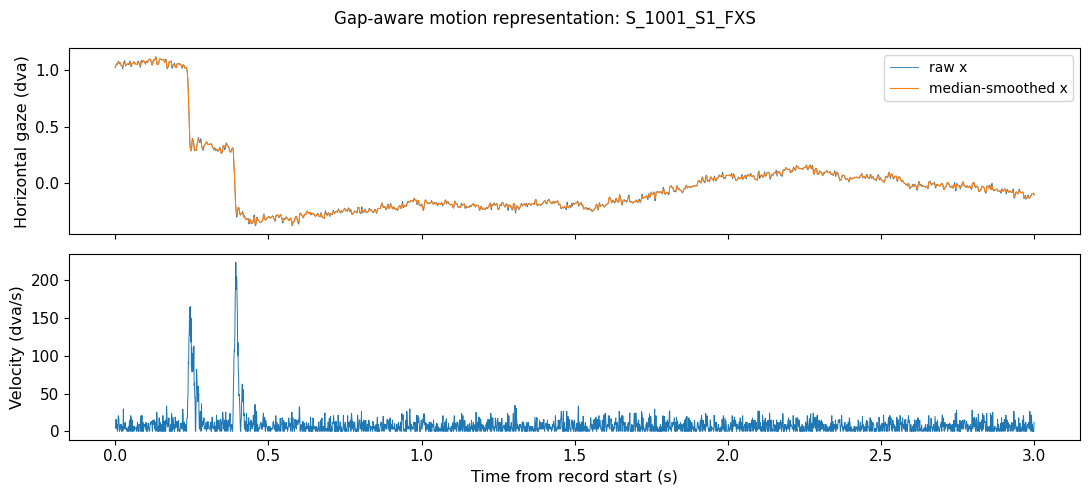

In [6]:
# ==================== 05. Compare Raw and Processed Gaze =====================

record_id = str(example_trace.record_id.iloc[0])
part = example_trace
fig, axes = plt.subplots(2,1, figsize=(11,5), sharex=True)
axes[0].plot(part.time_s, part.x, lw=0.6, label="raw x")
axes[0].plot(part.time_s, part.x_smooth, lw=0.8, label="median-smoothed x")
axes[0].set_ylabel("Horizontal gaze (dva)")
axes[0].legend()
axes[1].plot(part.time_s, part.velocity_dva_s, lw=0.7)
axes[1].set_ylabel("Velocity (dva/s)")
axes[1].set_xlabel("Time from record start (s)")
fig.suptitle(f"Gap-aware motion representation: {record_id}")
fig.tight_layout()
save_figure(fig, output_dir / "02_velocity_profile.png")
plt.show()


**06. Export Reusable Numerical Inputs**

Notebook 02 saves `02_preprocessed_samples.csv` (the complete processed sample table), `02_preprocessing_summary.csv` (record-level coverage and velocity diagnostics) and `02_velocity_profile.png` (the selected empirical trace). These are the **Notebook 02 outputs** and the sample table is the direct input to Notebook 03.

The ZIP created by the unchanged output-download helper is a portable copy of those current outputs; it is not a scientific result in its own right. Keep the potentially large ZIP and CSV private, and inspect record counts, missing boundary velocities and the saved plot before proceeding.


In [7]:
# =================== 06. Export Reusable Numerical Inputs ====================

print("Missing velocities at segment starts remain NaN.")
print("Current motion representation:", output_dir / "02_preprocessed_samples.csv")
download_outputs_from_colab("eye_tracking_foundations/output", "02")


Missing velocities at segment starts remain NaN.
Current motion representation: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output/02_preprocessed_samples.csv
------------------------------------------------------------------------
Notebook 02
Files packaged: 3
  + 02_preprocessed_samples.csv
  + 02_preprocessing_summary.csv
  + 02_velocity_profile.png
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_02_Outputs.zip
